# 3D Computer Vision (2026/27) - Exercise Sheet 1

---

**Release:** 29.10.2026  
**Deadline:** 09.11.2026, 23:59  
**Exercise session:** 12.11.2026 (mandatory)

**Group:** 10  
**Members:** Le Bao Anh, Haiyun Jiang, Pardha Saradhi Lanka, Junwei Lu

### Submission

Submit one `groupXX_exercise01.zip` in OLAT. It must contain a folder `groupXX_exercise01/` with your completed notebook, an HTML export showing all outputs, and the `data/` directory needed to run it. Use relative data paths. Install the packages from `requirements.txt` if needed.

By submitting, you confirm that all listed members contributed, no unlisted people were involved, and no solution content was copied from other people, large language models, websites, or other sources.

Attendance at the exercise session is mandatory. A group will be chosen at random to explain its solution. Be prepared to explain your work; failing to do so results in failing the task.

### Implementation

Complete the TODO cells using the models and derivations from the lecture slides. Implement the required vision steps yourself. NumPy operations, image I/O, plotting, and the provided utilities are allowed. Functions that perform undistortion or camera projection for you (such as `cv2.undistort`, `cv2.initUndistortRectifyMap`, or `cv2.projectPoints`) do not count as a solution.

---

# Theory Questions

## Task 1 — From a world point to a pixel

Given a world point $(X_s, Y_s, Z_s)$ and the camera's intrinsic and extrinsic parameters, write the complete transformation chain as matrix multiplications to obtain the pixel position $(u, v)$. Your final result must have two coordinates.

$\begin{pmatrix}u'\\v'\\w\end{pmatrix} = K [I_3|0_3] \begin{pmatrix}R &t\\0_3^T &1\end{pmatrix} \begin{pmatrix}X_s\\ Y_s\\ Z_s \\ 1\end{pmatrix}$

or

$\begin{pmatrix}u'\\v'\\w\end{pmatrix} = K \begin{pmatrix}R &t\end{pmatrix} \begin{pmatrix}X_s\\ Y_s\\ Z_s \\ 1\end{pmatrix}$

$u = \frac{u'}{w}, v = \frac{v'}{w}$

## Task 2 — Radial distortion

A point $\mathbf{p}$ in normalized image coordinates has distance $r=1$ from the origin. The radial distortion coefficients are $k_1=0.4$ and $k_2=0.1$, and

$$\mathbf{p}_d - \mathbf{p} = \begin{pmatrix}0.3 \\ 0.4\end{pmatrix},$$

where $\mathbf{p}_d$ is the radially distorted point. Derive the coordinates of $\mathbf{p}$.

For radial distortion,

$$\mathbf{p}_d = \mathbf{p}\left(1+k_1r^2+k_2r^4\right),$$

so

$$\mathbf{p}_d-\mathbf{p}
=\mathbf{p}\left(k_1r^2+k_2r^4\right)
=0.5\mathbf{p}.$$

Therefore,

$$\mathbf{p}
=\frac{1}{0.5}\begin{pmatrix}0.3\\0.4\end{pmatrix}
=\begin{pmatrix}0.6\\0.8\end{pmatrix}.$$

This satisfies $\|\mathbf{p}\|=1$.

# Implementation Task - Image undistortion and 3D point projection

## Task Overview and Given Data

Your overall task in this exercise will be to undistort the given images and project two given 3D points in all undistortedn images.

You will be given the following data:
- **9 color images** of the scene in `data/images/`
    - 8 Bit RGB per pixel
    - Each image rendered from a different position but with the same camera
    - The camera used had **lens distortion**
- 1 Dictionary containing **camera calibration parameters** in `data/camera_calibration.npy`
    - They belong to the camera that was used to render the RGB images
    - Distortion coefficients are given in the standard [k<sub>1</sub>, k<sub>2</sub>, p<sub>1</sub>, p<sub>2</sub>, k<sub>3</sub>] order
- 1 NumPy array containing **9 world-to-camera transformations** in `data/world_to_camera.npy`.
    - Shape `(9, 4, 4)`; entry `i` maps world coordinates directly to camera coordinates for image `view_names[i]`.
    - The world frame is camera 00, so entry 0 is the identity matrix.
- 1 CSV file containing two 3D points in `data/points_3d.csv`
    - Both points are **actual scene landmarks** of the upper and lower bend of the handle on the open cupboard door
    - Both landmarks are visible in all nine provided images
    - **World frame = the first camera frame (view 00)**

Note: Pixel coordinates use `(x, y)` (equivalently `(u, v)`); NumPy images are indexed as `[y, x]`.

The following cell loads the data and creates the output directory.

In [1]:
from pathlib import Path
import csv
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path.cwd()

if not (ROOT / 'data/camera_calibration.npy').is_file():
    if (ROOT.parent / 'data/camera_calibration.npy').is_file():
        ROOT = ROOT.parent
    else:
        raise FileNotFoundError('Extract the exercise pack and open Jupyter in its folder.')
   
DATA = ROOT / 'data'
OUTPUT = ROOT / 'output'
OUTPUT.mkdir(exist_ok=True)

calibration = np.load(DATA / 'camera_calibration.npy', allow_pickle=True).item()

image_paths = sorted((DATA / 'images').glob('*.png'))

view_names = [p.stem for p in image_paths]

images = np.stack([np.asarray(Image.open(p).convert('RGB'), dtype=np.float64) / 255.0
                   for p in image_paths])
n_views, height, width, _ = images.shape

print(n_views, height, width, _)
# print(images)

print(f"\nCamera Calibration:")
for entry in calibration.items():
    print(f"  {entry[0]}: {entry[1]}")


with (DATA / 'points_3d.csv').open(newline='') as f:
    point_rows = list(csv.DictReader(f))
point_labels = [row['point_id'] for row in point_rows]
points_world = np.array([[float(row[key]) for key in ('X', 'Y', 'Z')]
                         for row in point_rows])

point_descriptions = [row['landmark'] for row in point_rows]
print('Given 3D points in the world (camera-00) frame:')
for label, point, description in zip(point_labels, points_world, point_descriptions):
    print(label, point, '—', description)
    
world_to_camera = np.load(DATA / 'world_to_camera.npy', allow_pickle=False)
# print('World-to-camera matrices (one per view):')
# print(world_to_camera)
print(point_labels)

9 551 881 3

Camera Calibration:
  distortion_param: [-0.1, 0.02, 0.0, 0.0, -0.01]
  image_height: 551
  image_width: 881
  principal_point: [440.0, 275.0]
  focal_length_mm: 25
  sensor_width_mm: 35
  pixel_ratio: 1.0
  pixel_per_mm: 25.17142857142857
  focal_length_px: 629.2857142857142
  pixel_coordinate_order: xy
Given 3D points in the world (camera-00) frame:
H_top [-0.11179794  0.03925406  3.93998824] — Upper bend of the handle on the open cupboard door
H_bottom [-0.11391603  0.29837929  4.00820903] — Lower bend of the same cupboard-door handle
['H_top', 'H_bottom']


## Task 1 — Undistort the provided images by indirect transformation

Compute the output-to-input sampling grid, resample all nine RGB views,
and plot the results. Keep your `K` and `undistorted_images` variables:
Task 2 will reuse them directly.


### Provided sampling utility

`sample_image` interpolates colours at the source coordinates you supply. Compute the undistortion grid yourself.

In [2]:
def sample_image(image, source_grid):
    """Provided utility: bilinear sampling with zero padding.

    image: (H_source, W_source, 3), float RGB in [0, 1].
    source_grid: (H_target, W_target, 2), source coordinates in (x, y) order.
    The grid is never modified. Integer coordinates refer to pixel centres.
    """
    image = np.asarray(image, dtype=np.float64)
    source_grid = np.asarray(source_grid, dtype=np.float64)
    hs, ws, channels = image.shape
    finite = np.isfinite(source_grid).all(axis=-1)
    x_px = np.clip(np.where(finite, source_grid[..., 0], 0), -1, ws)
    y_px = np.clip(np.where(finite, source_grid[..., 1], 0), -1, hs)
    x0, y0 = np.floor(x_px).astype(int), np.floor(y_px).astype(int)
    dx, dy = x_px - x0, y_px - y0
    result = np.zeros(source_grid.shape[:-1] + (channels,), dtype=np.float64)
    for x_index, y_index, weight in [
        (x0,     y0,     (1-dx) * (1-dy)),
        (x0 + 1, y0,     dx * (1-dy)),
        (x0,     y0 + 1, (1-dx) * dy),
        (x0 + 1, y0 + 1, dx * dy),
    ]:
        valid = finite & (x_index >= 0) & (x_index < ws) & (y_index >= 0) & (y_index < hs)
        result[valid] += image[y_index[valid], x_index[valid]] * weight[valid, None]
    return result


### 1.1 — Camera intrinsics

Implement `make_intrinsics` to construct the 3×3 calibration matrix `K` from the supplied camera parameters.

In [3]:
def make_intrinsics(calibration):
    alpha_x = float(calibration['focal_length_px'])
    alpha_y = alpha_x
    
    u0, v0 = np.asarray(
        calibration['principal_point'],
        dtype=float
    )
    
    return np.array([
        [alpha_x, 0.0, u0],
        [0.0, alpha_y, v0],
        [0.0, 0.0, 1.0]
    ])

K = make_intrinsics(calibration)
print(K)

[[629.28571429   0.         440.        ]
 [  0.         629.28571429 275.        ]
 [  0.           0.           1.        ]]


### 1.2 — Forward lens-distortion model

Given a normalized image point compute the position of the distorted normalized image point using Brown's distortion model.
Implement this as a vectorized function that accepts and returns an array with shape `(..., 2)`, with x first and y second. 


In [4]:
def distort_normalized(normalized_xy_undistorted, coefficients):
    """Apply lens distortion to normalized image coordinates.

    Inputs:
        normalized_xy_undistorted: NumPy array, shape (..., 2),
            of undistorted normalized (x, y) points.
        coefficients: array-like, shape (5,),
            ordered [k1, k2, p1, p2, k3].

    Output:
        Distorted normalized (x, y) points as a floating-point
        NumPy array with shape (..., 2) and the same point order
        as normalized_xy_undistorted.
    """

    # Convert input to NumPy array with float64 data type
    normalized_xy_undistorted = np.asarray(
        normalized_xy_undistorted,
        dtype = np.float64
    )

    # Extract distortion coefficients
    k1, k2, p1, p2, k3 = np.asarray(
        coefficients,
        dtype = np.float64
    )

    # Extract undistorted normalized coordinates
    x_undistorted = normalized_xy_undistorted[..., 0]
    y_undistorted = normalized_xy_undistorted[..., 1]

    # Calculate squared radius
    r_squared = (
        x_undistorted**2 + y_undistorted**2
    )

    # Calculate radial distortion factor
    radial_factor = (
        1
        + k1 * r_squared
        + k2 * r_squared**2
        + k3 * r_squared**3
    )

    # Calculate distorted x coordinates
    x_distorted = (
        x_undistorted * radial_factor
        + 2 * p1 * x_undistorted * y_undistorted
        + p2 * (r_squared + 2 * x_undistorted**2)
    )

    # Calculate distorted y coordinates
    y_distorted = (
        y_undistorted * radial_factor
        + p1 * (r_squared + 2 * y_undistorted**2)
        + 2 * p2 * x_undistorted * y_undistorted
    )

    # Combine x and y coordinates
    distorted_xy = np.stack(
        (x_distorted, y_distorted),
        axis=-1
    )

    return distorted_xy

### 1.3 — Indirect geometric transformation (backward mapping)

For each **ideal output pixel** `(x, y)`, determine its colour-sampling
location in the **distorted input image**:

1. Build the output pixel grid in `(x, y)` order
2. Normalize the pixel coordinates
3. Apply the forward distortion model from Subtask 1.2
4. Denormalize the output 

Return a grid with shape `(H, W, 2)`, with each entry storing
`[source_x, source_y]`. Each output pixel requests one source sample,
which makes this an indirect image transformation.


In [5]:
def make_undistortion_grid(image_shape, K, coefficients):
    """Describe where each output pixel samples the distorted input image.

    Inputs:
        image_shape: tuple (H, W), the image height and width in pixels.
        K: NumPy array, shape (3, 3), the shared intrinsic matrix.
        coefficients: array-like, shape (5,), ordered [k1, k2, p1, p2, k3].
    Output:
        source_grid: floating-point NumPy array, shape (H, W, 2).
        source_grid[y, x] gives (source_x, source_y) in distorted-input pixels
        for the undistorted output pixel at (x, y).
    """
    # TODO: compute the output-to-input sampling grid.
    h, w = image_shape[:2]
    u_undistorted, v_undistorted = np.meshgrid(
        np.arange(w, dtype=float),
        np.arange(h, dtype=float),
        indexing='xy'
    )

    u0 = K[0, 2]
    v0 = K[1, 2]
    alpha_x = K[0, 0]
    alpha_y = K[1, 1]

    x_undistorted = (u_undistorted - u0) / alpha_x
    y_undistorted = (v_undistorted - v0) / alpha_y

    normalized_xy_undistorted = np.stack((x_undistorted, y_undistorted), axis=-1)

    normalized_xy_distorted = distort_normalized(
        normalized_xy_undistorted,
        coefficients
    )

    x_distorted = normalized_xy_distorted[..., 0]
    y_distorted = normalized_xy_distorted[..., 1]

    u_distorted = alpha_x * x_distorted + u0

    v_distorted = alpha_y * y_distorted + v0

    source_grid = np.stack([u_distorted, v_distorted], axis=-1)

    return source_grid


source_grid = make_undistortion_grid(
    (height, width),
    K,
    calibration['distortion_param']
)

assert source_grid.shape == (height, width, 2)
print('Sampling grid:', source_grid.shape, '; each entry is [source_x, source_y]')

Sampling grid: (551, 881, 2) ; each entry is [source_x, source_y]


### 1.4 — Resample all views

Use the provided `sample_image` with your grid. Store the results in `undistorted_images` with the same shape as `images`. Compute the shared grid only once. Save the undistorted RGB images under `output/task_1_undistorted/` using the original view filenames.


In [6]:
# TODO: sample all RGB views and save the undistorted images.
undistorted_list = [ sample_image(image, source_grid) for image in images]
undistorted_images = np.stack(undistorted_list)

assert undistorted_images.shape == images.shape

undistorted_dir = OUTPUT / 'task_1_undistorted'
undistorted_dir.mkdir(exist_ok=True)

for i in range(len(undistorted_images)):
    name = view_names[i]
    image = undistorted_images[i]
    image = np.clip(image, 0, 1)
    image = image * 255
    image = np.rint(image)
    image = image.astype(np.uint8)
    pil_image = Image.fromarray(image)
    output_path = undistorted_dir / (name + '.png')
    pil_image.save(output_path)

num_images = len(undistorted_images)

print(
    f'Undistorted {num_images} images; '
    f'saved to {undistorted_dir.name}/'
)

Undistorted 9 images; saved to task_1_undistorted/


### 1.5 — Plot your results

Create (a) a labelled before/after comparison for one view, and (b) a labelled gallery of **all nine undistorted views**. Use correct RGB colours and keep the image aspect ratio.


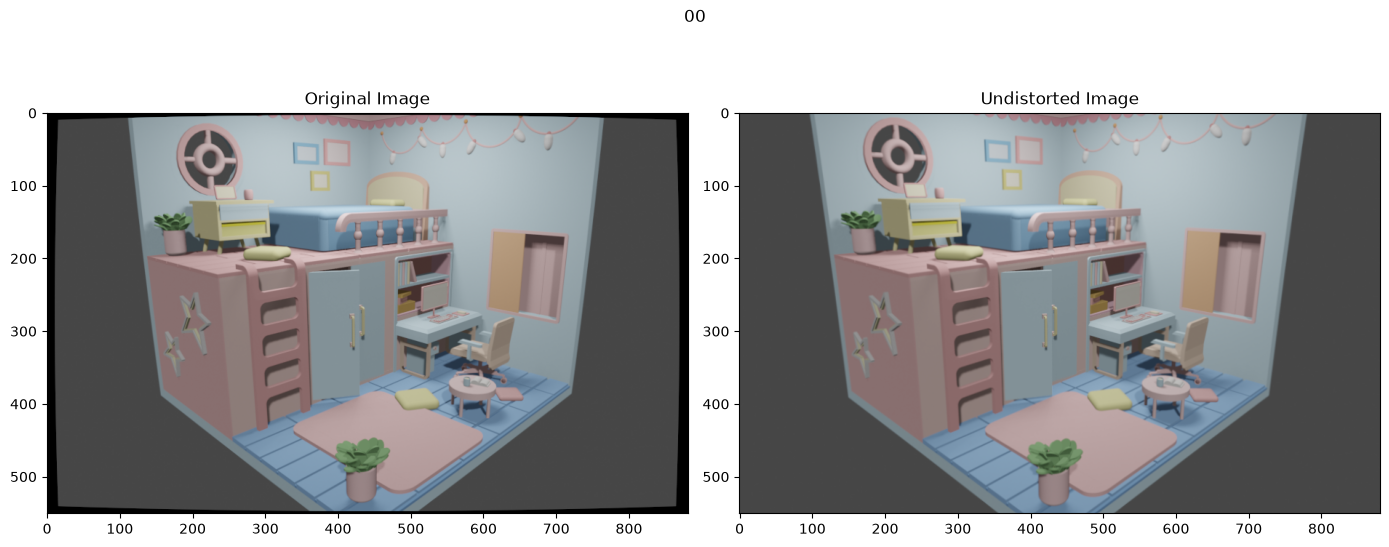

In [7]:
# TODO: plot one original image next to its undistorted version.
image_index = 0
original_image = images[image_index]
undistorted_image = undistorted_images[image_index]
image_name = view_names[image_index]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(original_image)
axes[0].set_title('Original Image')
axes[1].imshow(undistorted_image)
axes[1].set_title('Undistorted Image')

fig.suptitle(image_name)
plt.tight_layout()
plt.show()

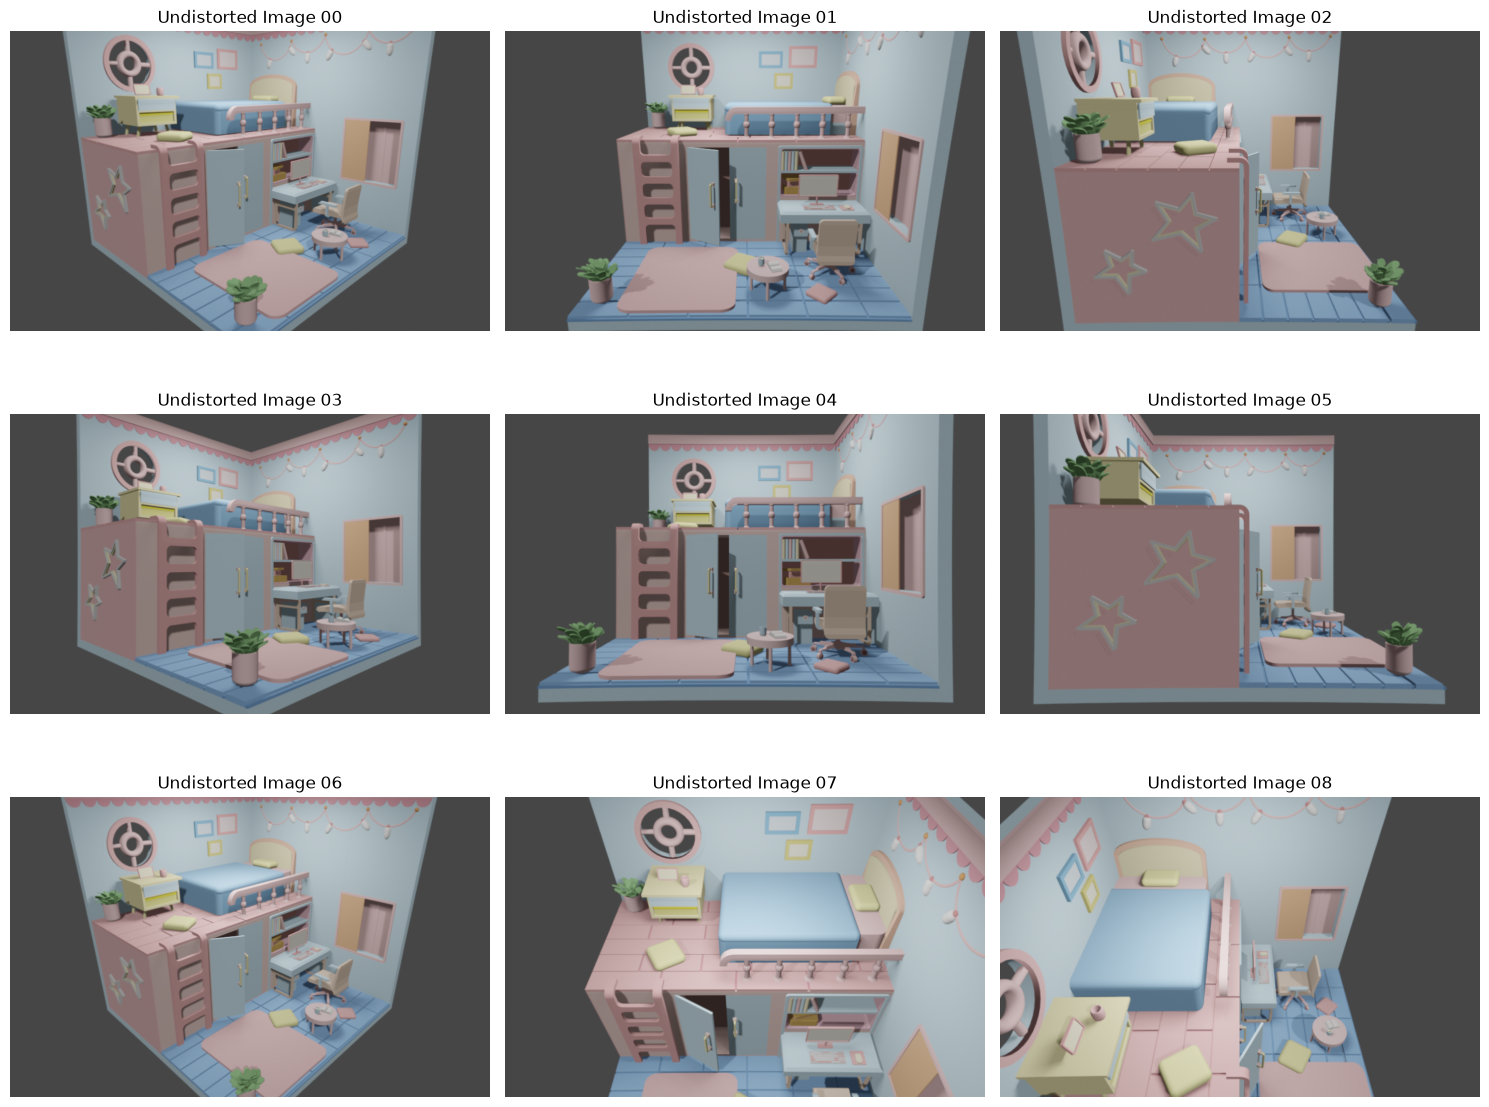

In [8]:
# TODO: plot all undistorted views in a labelled gallery.

fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for i in range(len(undistorted_images)):
    row = i // 3
    col = i % 3
    
    image = undistorted_images[i]
    name = 'Undistorted Image ' + view_names[i]

    axes[row, col].imshow(image)
    axes[row, col].set_title(name)
    axes[row, col].axis('off')

plt.tight_layout()
plt.show()

## Task 2 — Project the given 3D points into all views

Use **`undistorted_images` and `K` from Task 1** as the image backgrounds and
intrinsic matrix. Do not reload or overwrite them. You will use the
provided world-to-camera transformations, project the given points, and plot a labelled
gallery containing all nine views.



### 2.1 — Projection matrices and valid points

Implement `build_projection_matrix(E, K)` to construct a 3×4 projection matrix from a world-to-camera transform `E` and the intrinsic matrix `K`.

Implement `project_points(points_world, P)` to project the world points into one undistorted view. Return their floating-point pixel coordinates in `(x, y)` order, with shape `(N, 2)`.

In [9]:
def build_projection_matrix(E, K):
    """Build the projection matrix for one undistorted view.

    Inputs:
        E: NumPy array, shape (4, 4), mapping world to camera coordinates.
        K: NumPy array, shape (3, 3), the camera intrinsic matrix.
    Output:
        P: floating-point NumPy array, shape (3, 4), mapping homogeneous
        world points to homogeneous image coordinates for this view.
    """
    # TODO: construct P from K and E.
    # Matrix P = K[R|t]
    E = np.asarray(E, dtype=np.float64)
    K = np.asarray(K, dtype=np.float64)
    R_t = E[:3, :]
    return K @ R_t

In [10]:
def project_points(points_world, P):
    """Project world points into one undistorted view.

    Inputs:
        points_world: NumPy array, shape (N, 3); each row is a world point (X, Y, Z).
        P: NumPy array, shape (3, 4), the projection matrix for this view.
    Output:
        pixel_xy: floating-point NumPy array, shape (N, 2).
        Row j contains the pixel coordinates (x, y) of points_world[j].
    """
    # TODO: project the world points and return their pixel coordinates.
    points_world = np.asarray(points_world, dtype=float)
    P = np.asarray(P, dtype=float)
    
    num_points = len(points_world)
    # Create a new column vector Nx1
    ones = np.ones((num_points, 1), dtype=np.float64)

    points_world_homogeneous = np.concatenate(
        (points_world, ones),
        axis=1
    )

    projected_homogeneous = (
        P @ points_world_homogeneous.T
    ).T

    u_prime = projected_homogeneous[:, 0]
    v_prime = projected_homogeneous[:, 1]
    w_prime = projected_homogeneous[:, 2]

    u_pixel = u_prime / w_prime
    v_pixel = v_prime / w_prime

    return np.stack((u_pixel, v_pixel), axis=1)
    

### 2.3 — Project into every view

Build one projection matrix for each camera and store them in `projection_matrices`
with shape `(number_of_views, 3, 4)`. Use these matrices to project the points into every view and print the results.

In [11]:
# TODO: build the camera projection matrices and project the points.
# TODO: stack the results and print
projection_matrices = np.stack([
    build_projection_matrix(E, K) for E in world_to_camera
])

projections = [
    project_points(points_world, P)
    for P in projection_matrices
]

pixel_uv_all = np.stack([item for item in projections])
print(pixel_uv_all)

[[[422.14389393 281.26956666]
  [422.11527214 321.8453171 ]]

 [[376.37434279 282.68053963]
  [377.12600536 323.45678872]]

 [[479.72165775 289.84927865]
  [478.91407607 332.29295551]]

 [[421.46451685 284.55979415]
  [421.10752497 329.00150847]]

 [[373.91374642 284.64273087]
  [373.53672421 329.44351119]]

 [[481.38455266 285.06565715]
  [481.2941996  331.87819181]]

 [[423.67518816 313.08127566]
  [423.78791594 346.74664293]]

 [[367.04550479 444.01550254]
  [370.4896296  468.14409896]]

 [[485.25014269 471.08611678]
  [482.69011886 495.02959357]]]


### 2.4 — Plot the projections

Overlay the projected points on the undistorted Task 1 images in a 3-by-3 grid.
Use the same color and label for each point in every view.

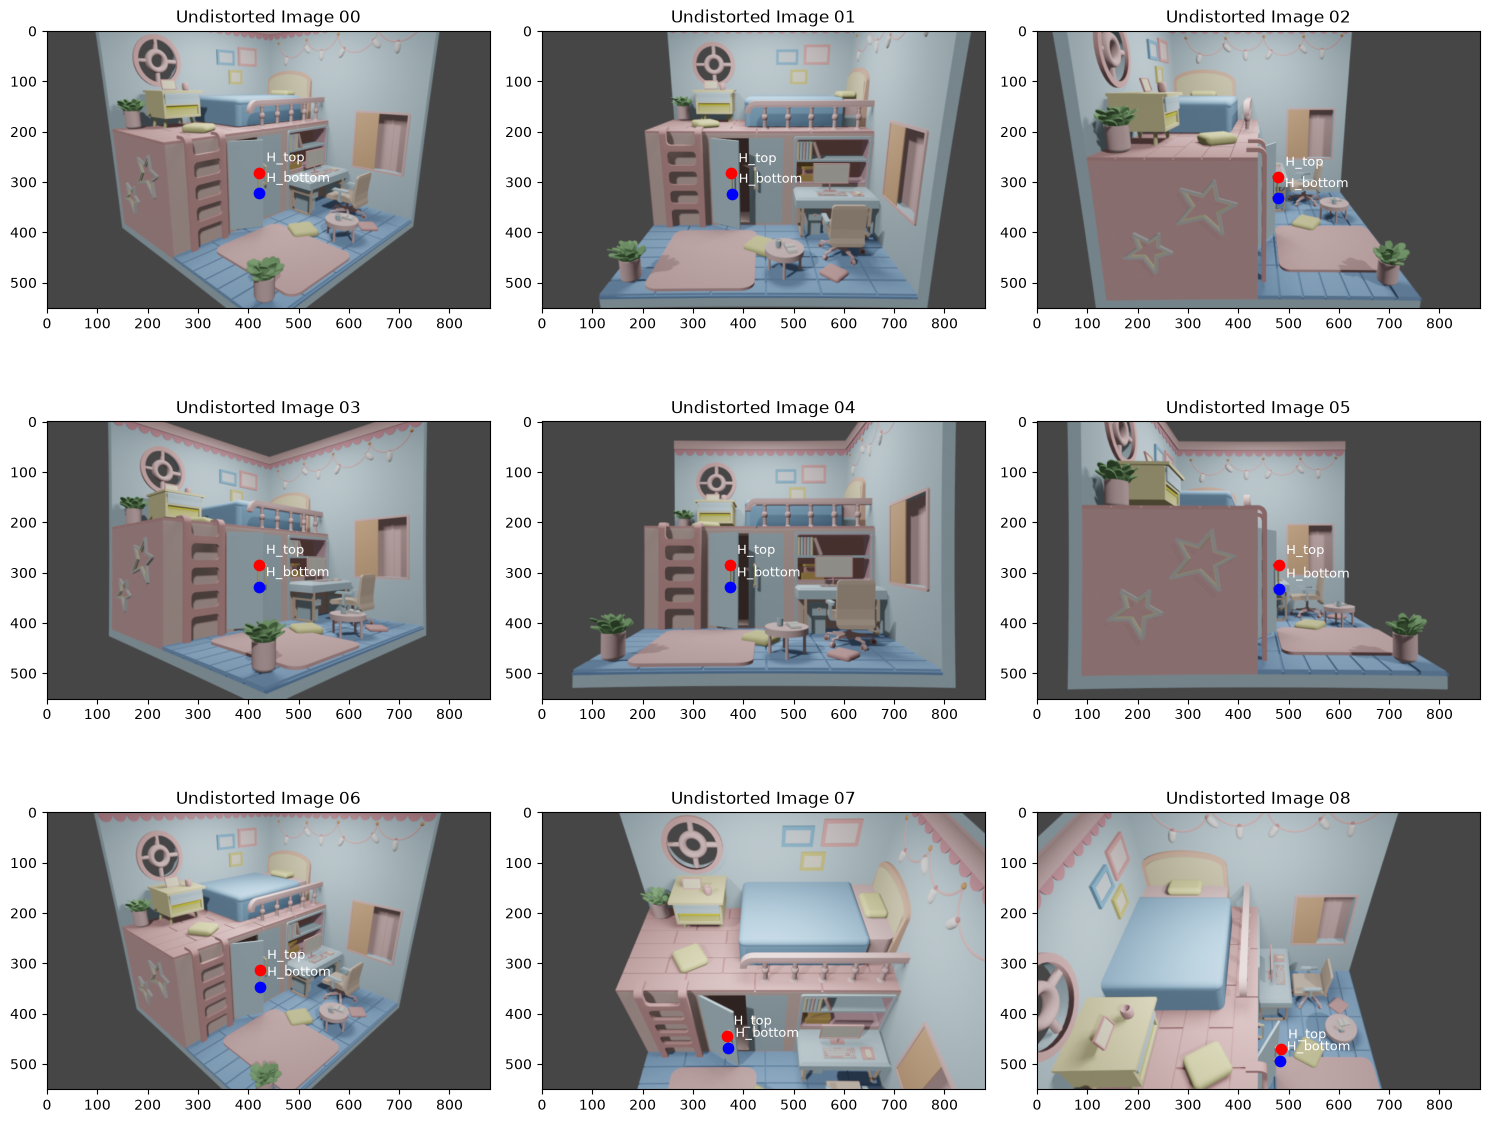

In [12]:
# TODO: plot the projections on undistorted_images for all views.

import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
colors = ['red', 'blue']

for i in range(len(undistorted_images)):

    ax = axes[i // 3, i % 3]
    ax.imshow(undistorted_images[i])

    for j, label in enumerate(point_labels):
        u, v = pixel_uv_all[i, j]
        ax.scatter(u, v, color=colors[j], s=55)
        ax.annotate(
            label,
            (u, v),
            xytext=(5, 8),
            textcoords='offset points',
            color='white',
            fontsize=9
        )

    ax.set_title('Undistorted Image ' + view_names[i])

plt.tight_layout()
plt.show()
